# Flow-Based Detection of VPN Traffic — Analysis

Supporting analysis for the ENGE817 report. Section numbers match the report.
Run top to bottom; a single seed governs every stochastic step.

Data: ISCXVPN2016, Scenario A1, 15-second flow timeout. Obtain from the Canadian
Institute for Cybersecurity and place the ARFF files under `../data/`.

In [1]:
import json, sys
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import sklearn
from scipy import stats
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

SEED = 42
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)
DATA = Path("../data/Scenario A1-ARFF")

print("xgboost", xgb.__version__, "| sklearn", sklearn.__version__,
      "| python", sys.version.split()[0])

C:\Users\SOKHOUR\anaconda3\envs\enge817\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


xgboost 3.2.0 | sklearn 1.9.0 | python 3.11.15


## 4.1 Dataset

The ARFF header is parsed to recover column names, since pandas does not read the
format directly. The loader is reused in 4.2.4 to check the other timeout files.

### Dataset provenance

The dataset authors recorded about 28 GB of real network traffic produced by members of
their laboratory. They covered seven kinds of activity, namely browsing, email, chat,
streaming, file transfer, voice calls, and peer-to-peer file sharing. Each activity was
recorded twice, once as an ordinary session and once tunnelled through a VPN using
OpenVPN in UDP mode. The recordings were then processed with a tool called ISCXFlowMeter,
which turns raw traffic into labelled flow records described by timing features. Both the
original recordings and the extracted features are publicly available.

### Classification scenarios

The dataset authors defined two classification scenarios. Scenario A works in two steps,
first separating VPN from non-VPN traffic and then identifying the kind of activity within
each group, whereas Scenario B identifies all fourteen activity types at once
(Draper-Gil et al., 2016). The features are distributed as three sets, labelled A1, A2 and
B. Scenario A1 at the 15-second flow timeout is used throughout this analysis.

![Classification scenarios provided with the dataset](../results/fig_scenarios.svg)

*The classification scenarios provided with the dataset. Only A1 is used in this study.*

### Flow directionality

The first packet of a flow sets the forward direction and traffic returning forms the
backward direction, which is why timing is reported separately for each. TCP flows
usually end when the connection closes rather than when the timeout expires, which is why
some run well beyond fifteen seconds.

*Relocated from report Section 4.1 during the 6,000-word trim (2026-09-13).*


In [2]:
def load_arff(path):
    """Parse an ARFF file into a DataFrame using its declared attribute names."""
    lines = Path(path).read_text(encoding="utf-8", errors="replace").splitlines()
    cols, start = [], None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.upper().startswith("@ATTRIBUTE"):
            cols.append(s.split()[1])
        elif s.upper().startswith("@DATA"):
            start = i + 1
            break
    frame = pd.read_csv(StringIO("\n".join(lines[start:])), header=None)
    frame = frame.iloc[:, :len(cols)]        # drop stray trailing columns
    frame.columns = cols
    return frame

df = load_arff(DATA / "TimeBasedFeatures-Dataset-15s-VPN.arff")
feature_cols = [c for c in df.columns if c != "class1"]

print(f"{len(df):,} flows, {len(feature_cols)} features")
print(df["class1"].value_counts(normalize=True).round(3).to_string())
df.head()

18,758 flows, 23 features
class1
VPN        0.522
Non-VPN    0.478


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,...,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,Non-VPN
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,...,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,Non-VPN
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,...,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,Non-VPN
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,...,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,Non-VPN
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,...,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,Non-VPN


### 4.2.1 Handling undefined values (-1)

The value -1 appears throughout the timing features. These record intervals and
durations, which cannot be negative under any unit, so -1 is a sentinel marking a
statistic the extraction tool could not compute.

#### Check 1 — Which features are affected, and how badly?

The missing values are concentrated in the four active and idle features, each undefined
in 60.5% of flows, while the forward and backward inter-arrival features are affected in
14.1% to 19.4% and the flow inter-arrival features in under 4%. This matches the
explanation above, since a flow must be long enough to pause and resume before it can
have an active or idle period at all.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


min_idle       60.5
max_idle       60.5
max_active     60.5
min_active     60.5
min_biat       19.4
total_biat     19.4
total_fiat     14.1
min_fiat       14.1
min_flowiat     3.1
max_flowiat     2.8


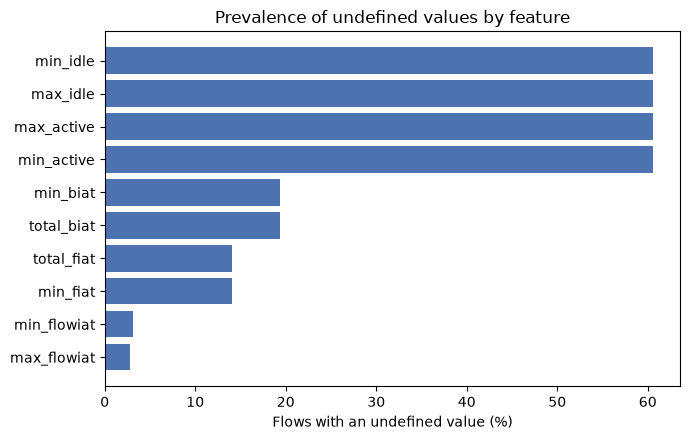

In [3]:
undef = (df[feature_cols] == -1).mean() * 100
undef = undef[undef > 0].sort_values(ascending=False)
print(undef.round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(undef.index[::-1], undef.values[::-1], color="#4C72B0")
ax.set_xlabel("Flows with an undefined value (%)")
ax.set_title("Prevalence of undefined values by feature")
plt.tight_layout()
plt.savefig(RESULTS / "fig_undefined_by_feature.png", dpi=150, bbox_inches="tight")
plt.show()

#### Check 2 — How many flows are affected?

Of the 18,758 flows, 11,663 contain at least one undefined value, which is 62.2% of the
total. Deleting the affected rows is therefore not an option, since it would discard
almost two thirds of the data and would remove short flows in particular, leaving a
sample biased towards longer sessions.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [4]:
affected = (df[feature_cols] == -1).any(axis=1)
print(f"Flows with at least one undefined value: {affected.sum():,} ({affected.mean():.1%})")
print(f"Undefined values in total: {(df[feature_cols] == -1).sum().sum():,}")

Flows with at least one undefined value: 11,663 (62.2%)
Undefined values in total: 59,089


#### Check 3 — Do undefined values carry class information?

This matters because a treatment that erased a genuine signal would be a poor choice.
Undefined values are common in both classes, affecting 57.8% of VPN flows and 66.9% of
non-VPN flows. Non-VPN traffic is therefore somewhat more likely to produce short flows
with missing statistics, but a gap of nine percentage points is modest, so the problem
belongs to neither class in particular. Re-coding the markers as missing preserves this
modest class-related pattern, which imputation would erase.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [5]:
# Reported within class, so the two rates are directly comparable
by_class = df.assign(u=affected).groupby("class1")["u"].agg(["sum", "count", "mean"])
by_class.columns = ["affected", "total", "within_class_rate"]
print(by_class.assign(within_class_rate=lambda d: (d.within_class_rate*100).round(1)).to_string())

         affected  total  within_class_rate
class1                                     
Non-VPN      6002   8965               66.9
VPN          5661   9793               57.8


**Decision.** Deletion would discard most of the data and bias the sample toward long
flows. Imputation would invent measurements that do not exist. The sentinels are recoded
as missing, which XGBoost handles natively through sparsity-aware split finding.

In [6]:
df_clean = df.copy()
df_clean[feature_cols] = df_clean[feature_cols].replace(-1, np.nan)
print(f"NaNs after recoding: {df_clean[feature_cols].isna().sum().sum():,}")

NaNs after recoding: 59,089


### 4.2.2 Outlier treatment

Two apparent anomalies: flows of zero duration, and per-second rates of extreme
magnitude. The question is whether either reflects genuine traffic.

#### Check 1 — How extreme are the distributions?

All three are heavily skewed towards small values, with a long tail of large ones. The
typical flow lasts 11.1 seconds and sends 11.7 packets per second, yet the fastest of all
reaches a million packets per second. The longest flow runs for 601 seconds, far beyond
the fifteen-second timeout, which is explained by the way TCP flows end. The
distributions taper off gradually rather than breaking into a separate cluster, which is
how genuine traffic behaves.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


duration             median 11,092,626.5  p99   60,239,487.8  max  601,404,954.0
flowPktsPerSecond    median         11.7  p99       48,780.5  max    1,000,000.0
flowBytesPerSecond   median      2,657.1  p99    5,746,109.3  max  617,000,000.0


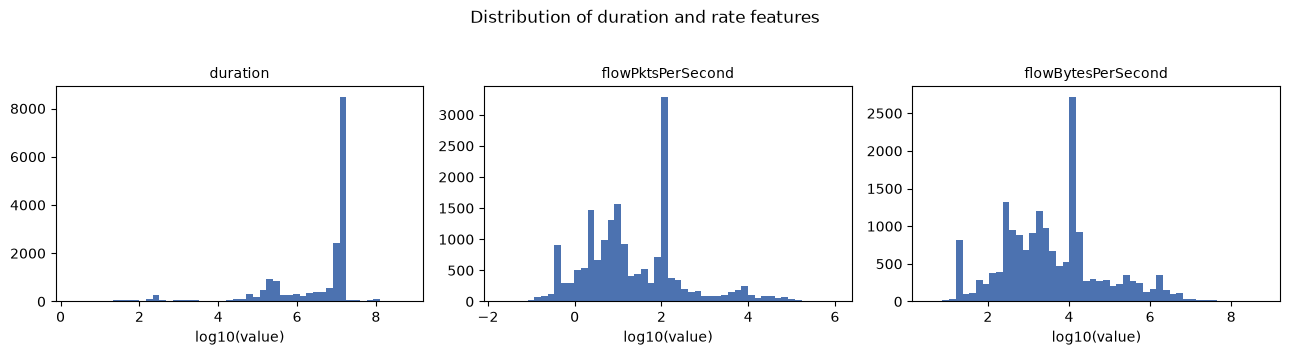

In [7]:
for c in ["duration", "flowPktsPerSecond", "flowBytesPerSecond"]:
    s = df_clean[c].dropna()
    print(f"{c:<20} median {s.median():>12,.1f}  p99 {s.quantile(.99):>14,.1f}  max {s.max():>14,.1f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["duration", "flowPktsPerSecond", "flowBytesPerSecond"]):
    v = df_clean[c].dropna(); v = v[v > 0]
    ax.hist(np.log10(v), bins=50, color="#4C72B0")
    ax.set_title(c, fontsize=10); ax.set_xlabel("log10(value)")
fig.suptitle("Distribution of duration and rate features", y=1.03)
plt.tight_layout()
plt.savefig(RESULTS / "fig_rate_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

#### Check 2 — The zero-duration flows

There are 532 of them, which is 2.84% of the dataset, and every one is entirely empty,
with a duration of zero, zero packets and bytes per second, and no value for any of the
ten timing statistics.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [8]:
zero_dur = df_clean["duration"] == 0
print(f"Zero-duration flows: {zero_dur.sum():,} ({zero_dur.mean():.2%})")
print("\nWithin each class (%):")
print((df_clean.assign(z=zero_dur).groupby("class1")["z"].mean()*100).round(2).to_string())

sub = df_clean.loc[zero_dur, feature_cols]
print("\nEvery feature zero or undefined in these records:",
      bool((sub.fillna(0) == 0).all().all()))

Zero-duration flows: 532 (2.84%)

Within each class (%):
class1
Non-VPN    2.30
VPN        3.33

Every feature zero or undefined in these records: True


#### Check 3 — Are the extreme rates an artefact of tiny durations?

They are not. The nineteen fastest flows all have real durations of between two and seven
microseconds, and none belongs to the zero-duration group. Because a rate is a count
divided by a duration, no flow can fall below the diagonal boundary in the plot below,
and the fastest flows sit on that boundary rather than beyond it, so the extreme rates
are arithmetic rather than faulty. The 532 zero-duration flows cannot be shown, since
neither axis is defined at zero.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


Flows at/above the 99.9th percentile of packet rate: 19
  durations (us): 2 to 7
  overlap with the zero-duration group: 0


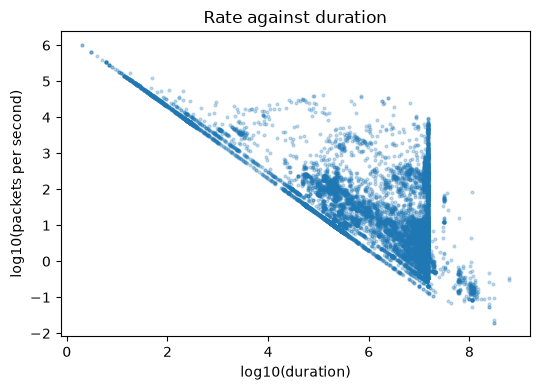

In [9]:
hi = df_clean["flowPktsPerSecond"] >= df_clean["flowPktsPerSecond"].quantile(0.999)
print(f"Flows at/above the 99.9th percentile of packet rate: {hi.sum()}")
print(f"  durations (us): {df_clean.loc[hi,'duration'].min():.0f} to {df_clean.loc[hi,'duration'].max():.0f}")
print(f"  overlap with the zero-duration group: {(hi & zero_dur).sum()}")

d = df_clean[(df_clean.duration > 0) & (df_clean.flowPktsPerSecond > 0)]
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(np.log10(d["duration"]), np.log10(d["flowPktsPerSecond"]), s=4, alpha=0.25)
ax.set_xlabel("log10(duration)"); ax.set_ylabel("log10(packets per second)")
ax.set_title("Rate against duration")
plt.tight_layout()
plt.savefig(RESULTS / "fig_rate_vs_duration.png", dpi=150, bbox_inches="tight")
plt.show()

**Decision.** The skewed rates are retained: the values are correctly computed, and tree
models split on order rather than magnitude. The zero-duration records are removed as
extraction artefacts, since every one of their features is zero or undefined.

In [10]:
df_clean = df_clean.loc[~zero_dur].reset_index(drop=True)
print(f"{len(df):,} -> {len(df_clean):,} flows")

18,758 -> 18,226 flows


### 4.2.3 Duplicate records

Identical rows appearing in both partitions would allow evaluation on memorised examples.

At this stage 338 of 18,226 flows share their feature values with at least one other
flow, which is 1.85% of the data. Taken together with the empty records removed in 4.2.2,
retaining only the first occurrence of each exact repeat is a reduction of 722 flows, or
3.8%, from the original 18,758.

The twenty-six patterns appearing with both labels were kept. Flows identical in every
feature were recorded as VPN in one case and non-VPN in another. No model can separate
two such flows, since it must return the same answer for both and one will always be
wrong.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [11]:
dup_feat = df_clean.duplicated(subset=feature_cols, keep=False)
dup_full = df_clean.duplicated(subset=feature_cols + ["class1"], keep=False)

print(f"Rows sharing feature values with another: {dup_feat.sum():,} ({dup_feat.mean():.2%})")
print(f"  also sharing the label (exact duplicates): {dup_full.sum():,}")

# Same features, different label. Retained: these are genuine observations, and removing
# them would discard the hardest cases and flatter the reported performance.
conflict = df_clean[dup_feat & ~dup_full]
print(f"  conflicting: {len(conflict):,} flows in "
      f"{conflict.groupby(feature_cols, dropna=False).ngroups} patterns")

Rows sharing feature values with another: 338 (1.85%)
  also sharing the label (exact duplicates): 309
  conflicting: 29 flows in 19 patterns


In [12]:
# A pattern is conflicting if the same feature values appear with both labels.
# Count every flow in such a pattern, not only the minority rows, since the
# earlier measure captures only rows outside the exact-duplicate groups.
pattern_labels = df_clean.groupby(feature_cols, dropna=False)["class1"].nunique()
conflicting = pattern_labels[pattern_labels > 1]

mask = df_clean.set_index(feature_cols).index.isin(conflicting.index)

print(f"Conflicting patterns : {len(conflicting)}")
print(f"Flows involved       : {mask.sum()}")
print(f"Share of dataset     : {mask.mean():.2%}")

Conflicting patterns : 22
Flows involved       : 62
Share of dataset     : 0.34%


In [13]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=feature_cols + ["class1"], keep="first").reset_index(drop=True)
print(f"{before:,} -> {len(df_clean):,}  ({before-len(df_clean):,} exact duplicates removed)")
print(df_clean["class1"].value_counts(normalize=True).round(3).to_string())

18,226 -> 18,036  (190 exact duplicates removed)
class1
VPN        0.518
Non-VPN    0.482


### 4.2.4 Validity of the feature definitions

The checks above examined recorded values. This one examines the columns themselves.
Three feature groups are published as a minimum, mean and maximum of one quantity, so the
mean must lie between the other two.

Three of the five feature groups measure the interval between successive packets,
differing only in which packets are counted. These features were proposed by the authors
of the dataset as discriminative of tunnelled traffic, on the reasoning that encapsulation
and the additional routing a tunnel requires alter the rhythm with which packets arrive.

![The three inter-arrival features](../results/fig_iat_definitions.svg)

*The three inter-arrival features, shown for a single flow of seven packets. Forward
counts the intervals between packets travelling from source to destination, backward
those returning, and flow those between consecutive packets in either direction. The
dataset records the minimum, mean, and maximum of each.*

*Relocated from the report during the 6,000-word trim (2026-09-13).*


#### Consistency of the published triples

In [14]:
groups = ["fiat", "biat", "flowiat", "active", "idle"]

def consistency(frame, grp):
    t = frame[[f"min_{grp}", f"mean_{grp}", f"max_{grp}"]].replace(-1, np.nan).dropna()
    return ((t[f"min_{grp}"] <= t[f"mean_{grp}"]) &
            (t[f"mean_{grp}"] <= t[f"max_{grp}"])).mean() * 100

print("Flows satisfying min <= mean <= max (%)\n")
for g in groups:
    print(f"  {g:<9} {consistency(df, g):5.1f}")

Flows satisfying min <= mean <= max (%)

  fiat        0.0
  biat        0.0
  flowiat    99.9
  active     72.0
  idle       80.5


#### What form do the failures take?

In [15]:
for g in ["fiat", "biat", "flowiat"]:      # flowiat as a control
    t = df[[f"min_{g}", f"mean_{g}", f"max_{g}"]].replace(-1, np.nan).dropna()
    lo = t[[f"min_{g}", f"max_{g}"]].min(axis=1)
    hi = t[[f"min_{g}", f"max_{g}"]].max(axis=1)
    print(f"{g:<9} as labelled {(t[f'min_{g}'] <= t[f'max_{g}']).mean():6.1%}"
          f" | reversed {(t[f'max_{g}'] <= t[f'min_{g}']).mean():6.1%}"
          f" | mean below pair {(t[f'mean_{g}'] < lo).mean():6.1%}"
          f" | above {(t[f'mean_{g}'] > hi).mean():6.1%}")

fiat      as labelled   7.5% | reversed  99.7% | mean below pair  46.3% | above   0.0%
biat      as labelled   4.0% | reversed  99.5% | mean below pair  44.0% | above   0.0%
flowiat   as labelled 100.0% | reversed  13.2% | mean below pair   0.0% | above   0.0%


#### Does the pattern hold across the other flow timeouts?

Percentage of flows satisfying the condition that the mean lies between the minimum and
the maximum, by feature group and flow timeout:

| Feature group | 15s | 30s | 60s | 120s |
|---|---|---|---|---|
| Forward inter-arrival | 0.0 | 0.0 | 88.3 | 0.0 |
| Backward inter-arrival | 0.0 | 0.0 | 87.0 | 0.0 |
| Flow inter-arrival | 99.9 | 99.5 | 99.9 | 99.9 |
| Active | 72.0 | 62.8 | 58.0 | 67.1 |
| Idle | 80.5 | 70.7 | 64.9 | 69.9 |

The same pattern holds across the other flow-timeout files, except the 60-second file in
which the forward and backward groups are largely consistent. The files therefore differ
from one another, which indicates that the discrepancy arises during generation of the
published files rather than in any single release. They were examined only to test whether
the problem was confined to the file used for modelling.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


,15s,30s,60s,120s
fiat,0.0,0.0,88.3,0.0
biat,0.0,0.0,87.0,0.0
flowiat,99.9,99.5,99.9,99.9
active,72.0,62.8,58.0,67.1
idle,80.5,70.7,64.9,69.9


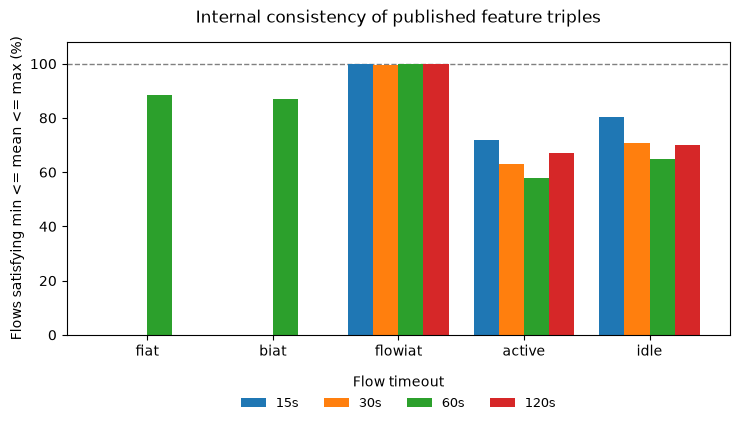

In [16]:
timeouts = ["15s", "30s", "60s", "120s"]
table = pd.DataFrame(index=groups, columns=timeouts, dtype=float)
for t in timeouts:
    d = load_arff(DATA / f"TimeBasedFeatures-Dataset-{t}-VPN.arff")
    for g in groups:
        table.loc[g, t] = consistency(d, g)
display(table.round(1))

fig, ax = plt.subplots(figsize=(7.5, 4.4))
x = np.arange(len(groups)); w = 0.2
for i, t in enumerate(timeouts):
    ax.bar(x + (i-1.5)*w, table[t], w, label=t)

ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylabel("Flows satisfying min <= mean <= max (%)")
ax.set_ylim(0, 108)
ax.axhline(100, ls="--", color="grey", lw=1, zorder=0)
ax.set_title("Internal consistency of published feature triples", pad=14)

# Legend below the axes, so it cannot overlap the bars
ax.legend(title="Flow timeout", ncol=4, frameon=False, fontsize=9,
          loc="upper center", bbox_to_anchor=(0.5, -0.10))

plt.tight_layout()
plt.savefig(RESULTS / "fig_feature_consistency.png", dpi=150, bbox_inches="tight")
plt.show()

#### Columns that cannot be reconciled with their descriptions

In [17]:
# The totals are documented as sums of inter-arrival times in microseconds
for c in ["total_fiat", "total_biat"]:
    s = df[c].replace(-1, np.nan).dropna()
    print(f"{c:<12} median {s.median():>10,.0f}  max {s.max():>14,.0f}  integers: {(s % 1 == 0).all()}")
print(f"\nMedian flow duration (us): {df['duration'].median():,.0f}")

implied = df["flowPktsPerSecond"] * df["duration"] / 1e6
print("corr(total_fiat + total_biat, implied packet count):",
      round((df["total_fiat"] + df["total_biat"]).corr(implied), 3))

# Duplicate columns
pair = df[["max_flowiat", "max_idle"]].replace(-1, np.nan).dropna()
print(f"\nmax_flowiat == max_idle in {(pair['max_flowiat']==pair['max_idle']).mean():.1%}"
      f" of the {len(pair):,} flows where both are defined")

total_fiat   median        102  max     37,680,787  integers: True
total_biat   median         42  max     43,002,377  integers: True

Median flow duration (us): 11,092,626
corr(total_fiat + total_biat, implied packet count): -0.046

max_flowiat == max_idle in 100.0% of the 7,403 flows where both are defined


**Decision.** The forward and backward inter-arrival groups fail systematically: the
minimum and maximum columns are transposed, and the column named as the mean falls outside
the range it should summarise. The cause could not be established, since the code that
generated the files is unavailable. These eight columns are excluded, because a feature
whose meaning cannot be stated cannot support an answer to SQ2.

The active and idle groups are retained: their failures affect a minority of flows and are
consistent with edge cases rather than a labelling error.

In [18]:
excluded = [c for c in feature_cols if c.endswith("_fiat") or c.endswith("_biat")]
feature_cols = [c for c in feature_cols if c not in excluded]

print(f"Excluded {len(excluded)}: {excluded}")
print(f"\nRetained {len(feature_cols)}:")
for c in feature_cols:
    print("   ", c)

Excluded 8: ['total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat']

Retained 15:
    duration
    flowPktsPerSecond
    flowBytesPerSecond
    min_flowiat
    max_flowiat
    mean_flowiat
    std_flowiat
    min_active
    mean_active
    max_active
    std_active
    min_idle
    mean_idle
    max_idle
    std_idle


### 4.2.5 Label encoding

VPN is the positive class, so precision, recall and F1 refer to the class of interest
in SQ1.

VPN is the positive class (1) and non-VPN the negative class (0). This is not merely a
formality, because precision, recall and F1-score are defined with respect to the positive
class, so reporting them for the VPN class directly addresses SQ1.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [19]:
df_clean["label"] = (df_clean["class1"] == "VPN").astype(int)
print(f"Positive (VPN): {df_clean['label'].sum():,} ({df_clean['label'].mean():.3f})")

Positive (VPN): 9,350 (0.518)


### 4.2.6 Data split

80:20, stratified. Tuning uses five-fold cross-validation inside the training set, so the
test partition is examined once, at the end.

The feature files carry no session identifier, so a grouped split is not possible. This
limitation is recorded in the report.

Missing values were deliberately carried through the split rather than filled, with 34,044
in the training set and 8,537 in the test set, so that XGBoost applies the native handling
described in 4.2.1.

*Relocated from the report during the 6,000-word trim (2026-09-13).*


In [20]:
X = df_clean[feature_cols]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Train {len(X_train):,} ({y_train.mean():.3f} VPN)")
print(f"Test  {len(X_test):,} ({y_test.mean():.3f} VPN)")
print(f"Features {X_train.shape[1]}")
print(f"Missing retained: {X_train.isna().sum().sum():,} train, {X_test.isna().sum().sum():,} test")

Train 14,428 (0.518 VPN)
Test  3,608 (0.518 VPN)
Features 15
Missing retained: 34,044 train, 8,537 test


## 5.1 Exploratory analysis

Training set only, so the test partition stays unexamined.

### 5.1.1 Univariate class separation

Each feature is ranked by how well it separates the classes alone, using the AUC implied
by the Mann-Whitney U statistic. 0.5 means no separation.

In [21]:
train = X_train.copy(); train["label"] = y_train.values
rows = []
for c in feature_cols:
    a = train.loc[train.label == 1, c].dropna()
    b = train.loc[train.label == 0, c].dropna()
    u, _ = stats.mannwhitneyu(a, b, alternative="two-sided")
    auc = u / (len(a) * len(b))
    rows.append({"feature": c, "sep_AUC": round(max(auc, 1-auc), 3),
                 "higher_in": "VPN" if a.median() > b.median() else "non-VPN"})
sep = pd.DataFrame(rows).sort_values("sep_AUC", ascending=False).reset_index(drop=True)
display(sep)

,feature,sep_AUC,higher_in
0,flowBytesPerSecond,0.621,non-VPN
1,flowPktsPerSecond,0.609,non-VPN
2,mean_flowiat,0.608,VPN
3,std_flowiat,0.605,VPN
4,max_flowiat,0.605,VPN
5,min_flowiat,0.572,VPN
6,mean_active,0.561,non-VPN
7,duration,0.560,non-VPN
8,mean_idle,0.556,non-VPN
9,min_active,0.530,VPN


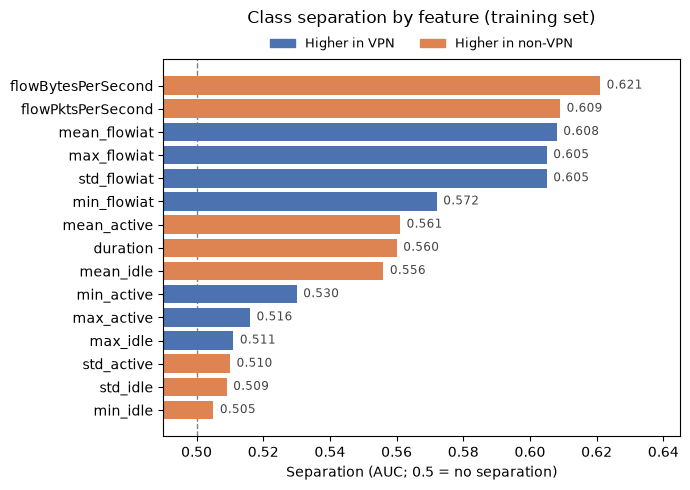

In [22]:
from matplotlib.patches import Patch
s = sep.sort_values("sep_AUC")
colours = ["#4C72B0" if h == "VPN" else "#DD8452" for h in s["higher_in"]]

from matplotlib.patches import Patch

s = sep.sort_values("sep_AUC")
colours = ["#4C72B0" if h == "VPN" else "#DD8452" for h in s["higher_in"]]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.barh(s["feature"], s["sep_AUC"], color=colours)

# 0.5 is chance, so start the axis just below it: bar length then shows
# how far above chance each feature reaches, rather than wasting half the plot
ax.set_xlim(0.49, 0.645)
ax.axvline(0.5, color="grey", ls="--", lw=1, zorder=0)

# Value at the end of each bar, so the axis need not be read
for bar, v in zip(bars, s["sep_AUC"]):
    ax.text(v + 0.002, bar.get_y() + bar.get_height()/2, f"{v:.3f}",
            va="center", fontsize=8.5, color="#444")

ax.set_xlabel("Separation (AUC; 0.5 = no separation)")
ax.set_title("Class separation by feature (training set)", pad=26)

# Legend above the axes, where no bar can reach it
ax.legend(handles=[Patch(color="#4C72B0", label="Higher in VPN"),
                   Patch(color="#DD8452", label="Higher in non-VPN")],
          loc="upper center", bbox_to_anchor=(0.5, 1.09), ncol=2,
          frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS / "fig_separation.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.1.2 Feature correlation

Correlated features split a tree model's attributions between them, which constrains how
the importance results in 5.3 can be read.

The retained features describe overlapping aspects of the same underlying traffic
behaviour, so a degree of correlation is expected. Correlation was measured using the
Spearman rank coefficient, for consistency with the rank-based separation measure.

![Spearman correlation matrix](../results/fig_correlation.png)

*Spearman correlation matrix for the fifteen retained features, measured on the training
set.*

The extent of that correlation constrains the interpretation of feature attribution,
because where two features carry equivalent information a tree ensemble divides its splits
between them and the importance attributed to each is correspondingly reduced. The
inter-arrival, active and idle features form a block of positively correlated variables,
since a flow with long intervals between packets necessarily exhibits long idle periods,
while the two rate features form a second block correlated negatively with the first,
because high throughput implies short intervals between packets.

Maximum flow inter-arrival time and maximum idle time hold identical values wherever both
are defined, since the longest interval between two packets is the longest idle period.
Both were retained, but the consequence for attribution is that any importance measure
recording how often a feature is used will divide the credit for this single quantity
between two columns.

*Relocated from the report during the word-budget trim (2026-09-13).*


Pairs |rho| >= 0.9 : 8
Pairs 0.8 to 0.9   : 15
Mean |rho|         : 0.515



abs_spearman
max_flowiat        max_idle                   1.000
std_active         std_idle                   0.996
flowPktsPerSecond  mean_flowiat               0.993
mean_active        mean_idle                  0.989
flowBytesPerSecond mean_flowiat               0.956
flowPktsPerSecond  flowBytesPerSecond         0.950
mean_idle          max_idle                   0.949
mean_active        max_active                 0.922
min_active         min_idle                   0.897
                   mean_active                0.894

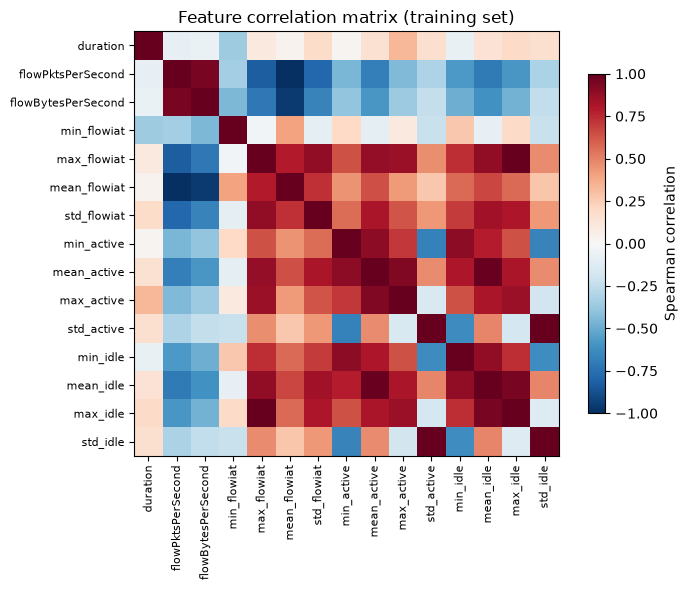

In [23]:
corr = X_train.corr(method="spearman")
pairs = (corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))

print(f"Pairs |rho| >= 0.9 : {(pairs >= 0.9).sum()}")
print(f"Pairs 0.8 to 0.9   : {((pairs >= 0.8) & (pairs < 0.9)).sum()}")
print(f"Mean |rho|         : {pairs.mean():.3f}\n")
display(pairs.head(10).round(3).to_frame("abs_spearman"))

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols))); ax.set_xticklabels(feature_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(feature_cols))); ax.set_yticklabels(feature_cols, fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Feature correlation matrix (training set)")
plt.tight_layout()
plt.savefig(RESULTS / "fig_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.2 Detection performance (SQ1)

### 5.2.1 Baseline model

Library defaults, so that any later gain is attributable to tuning rather than to prior
configuration.

In [24]:
baseline = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                             random_state=SEED, n_jobs=-1)

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring,
                     return_train_score=True, n_jobs=-1)

print("Baseline, stratified 5-fold CV on the training set\n")
for m in scoring:
    te, tr = res[f"test_{m}"], res[f"train_{m}"]
    print(f"{m:<10} val {te.mean():.4f} (+/- {te.std():.4f})   train {tr.mean():.4f}")

Baseline, stratified 5-fold CV on the training set

accuracy   val 0.8879 (+/- 0.0060)   train 0.9701
precision  val 0.8862 (+/- 0.0061)   train 0.9696
recall     val 0.8993 (+/- 0.0100)   train 0.9729
f1         val 0.8927 (+/- 0.0060)   train 0.9712
roc_auc    val 0.9610 (+/- 0.0019)   train 0.9959


### 5.2.2 Hyperparameter tuning

Randomised search, ranked by ROC-AUC on validation folds only, so configurations that fit
the training data too closely are penalised without any further constraint.

In [25]:
param_dist = {
    "n_estimators":     [200, 400, 600, 800],
    "max_depth":        [3, 4, 5, 6, 8],
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "subsample":        [0.6, 0.7, 0.8, 0.9],   # row sampling adds tree diversity
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9],   # feature sampling does the same
    "min_child_weight": [1, 3, 5, 10],          # minimum weight to form a leaf
    "gamma":            [0, 0.1, 0.5, 1.0],     # minimum gain to justify a split
    "reg_lambda":       [1, 3, 10],
}

search = RandomizedSearchCV(
    xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                      random_state=SEED, n_jobs=1),
    param_distributions=param_dist, n_iter=60, scoring="roc_auc", cv=cv,
    random_state=SEED, n_jobs=-1, return_train_score=True, verbose=1)

search.fit(X_train, y_train)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.7, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to sel

In [26]:
best, cvres = search.best_index_, search.cv_results_
print("Best CV ROC-AUC :", round(search.best_score_, 4))
print("Training ROC-AUC:", round(cvres["mean_train_score"][best], 4))
print("Gap             :", round(cvres["mean_train_score"][best] - search.best_score_, 4))
print("\nBest hyperparameters:")
for k, v in sorted(search.best_params_.items()):
    print(f"  {k:<18} {v}")

Best CV ROC-AUC : 0.9642
Training ROC-AUC: 0.997
Gap             : 0.0328

Best hyperparameters:
  colsample_bytree   0.7
  gamma              0.1
  learning_rate      0.05
  max_depth          8
  min_child_weight   3
  n_estimators       600
  reg_lambda         1
  subsample          0.8


In [27]:
# Does the gap respond to regularisation, or is it a property of the data?
r = pd.DataFrame(search.cv_results_)
r["gap"] = r["mean_train_score"] - r["mean_test_score"]
cols = ["rank_test_score", "mean_test_score", "mean_train_score", "gap",
        "param_max_depth", "param_learning_rate", "param_subsample"]
print("Top 10 by validation score:"); display(r.nsmallest(10, "rank_test_score")[cols].round(4))
print("Smallest gaps overall:");       display(r.nsmallest(5, "gap")[cols].round(4))

Top 10 by validation score:


,rank_test_score,mean_test_score,mean_train_score,gap,param_max_depth,param_learning_rate,param_subsample
11,1,0.9642,0.9970,0.0328,8,0.05,0.8
27,2,0.9641,0.9988,0.0347,8,0.10,0.9
49,3,0.9631,0.9963,0.0332,8,0.10,0.8
41,4,0.9628,0.9966,0.0338,8,0.10,0.8
3,5,0.9626,0.9956,0.0330,6,0.10,0.8
29,6,0.9623,0.9929,0.0307,8,0.03,0.7
17,7,0.9622,0.9933,0.0311,8,0.05,0.8
34,8,0.9617,0.9949,0.0332,6,0.10,0.8
10,9,0.9614,0.9919,0.0305,6,0.05,0.8
21,10,0.9613,0.9930,0.0318,5,0.05,0.7


Smallest gaps overall:


,rank_test_score,mean_test_score,mean_train_score,gap,param_max_depth,param_learning_rate,param_subsample
43,60,0.8613,0.8667,0.0054,3,0.01,0.8
51,59,0.8618,0.8674,0.0056,3,0.01,0.8
53,58,0.8805,0.8873,0.0068,3,0.01,0.6
58,57,0.8934,0.9014,0.0080,3,0.03,0.6
12,56,0.8982,0.9065,0.0083,3,0.03,0.9


### 5.2.3 Final evaluation on the test set

The test partition is used here for the first and only time. No selection or adjustment
follows.

![Confusion matrix](../results/fig_confusion.png)

*Confusion matrix for the tuned model on the test set.*

The weakest individual measure is recall for the non-VPN class at 0.8740, indicating that
the model recognises tunnelled traffic more reliably than it confirms the absence of
tunnelling.

*Relocated from the report during the word-budget trim (2026-09-13).*


In [28]:
final_model = search.best_estimator_
y_pred  = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("Test-set performance (VPN = positive)\n")
for name, fn in [("Accuracy", accuracy_score), ("Precision", precision_score),
                 ("Recall", recall_score), ("F1-score", f1_score)]:
    print(f"  {name:<10} {fn(y_test, y_pred):.4f}")
print(f"  {'ROC-AUC':<10} {roc_auc_score(y_test, y_proba):.4f}")
print(f"\nCV estimate for comparison: {search.best_score_:.4f}")
print("\n" + classification_report(y_test, y_pred, target_names=["Non-VPN","VPN"], digits=4))

Test-set performance (VPN = positive)

  Accuracy   0.8927
  Precision  0.8860
  Recall     0.9102
  F1-score   0.8979
  ROC-AUC    0.9653

CV estimate for comparison: 0.9642

              precision    recall  f1-score   support

     Non-VPN     0.9004    0.8740    0.8870      1738
         VPN     0.8860    0.9102    0.8979      1870

    accuracy                         0.8927      3608
   macro avg     0.8932    0.8921    0.8925      3608
weighted avg     0.8929    0.8927    0.8927      3608



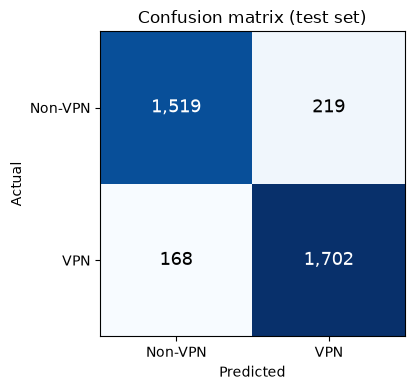

False positives 219 (12.6% of non-VPN)
False negatives 168 (9.0% of VPN)


In [29]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn_, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0,1]); ax.set_xticklabels(["Non-VPN","VPN"])
ax.set_yticks([0,1]); ax.set_yticklabels(["Non-VPN","VPN"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion matrix (test set)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center", fontsize=13,
                color="white" if cm[i,j] > cm.max()/2 else "black")
plt.tight_layout()
plt.savefig(RESULTS / "fig_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"False positives {fp:,} ({fp/(fp+tn):.1%} of non-VPN)")
print(f"False negatives {fn_:,} ({fn_/(fn_+tp):.1%} of VPN)")

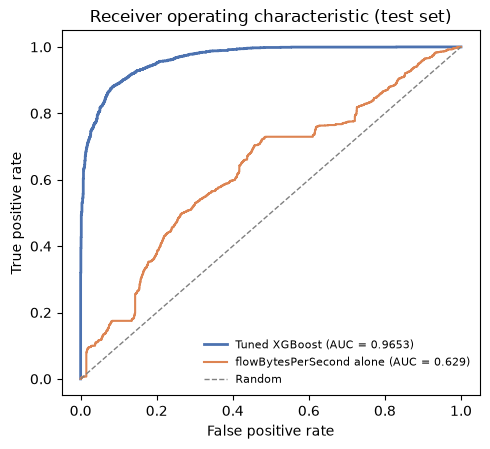

In [30]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

# Best single feature, for comparison. Negated when higher values indicate non-VPN.
bf = sep.iloc[0]["feature"]
sign = -1 if sep.iloc[0]["higher_in"] == "non-VPN" else 1
sf = sign * X_test[bf].fillna(X_test[bf].median())
fpr_sf, tpr_sf, _ = roc_curve(y_test, sf)

fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot(fpr, tpr, color="#4C72B0", lw=2,
        label=f"Tuned XGBoost (AUC = {roc_auc_score(y_test, y_proba):.4f})")
ax.plot(fpr_sf, tpr_sf, color="#DD8452", lw=1.5,
        label=f"{bf} alone (AUC = {roc_auc_score(y_test, sf):.3f})")
ax.plot([0,1], [0,1], "--", color="grey", lw=1, label="Random")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Receiver operating characteristic (test set)")
ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(RESULTS / "fig_roc.png", dpi=150, bbox_inches="tight")
plt.show()

#### Confidence intervals

Percentile intervals from resampling the test predictions, so the precision of each
estimate is stated rather than assumed.

In [31]:
rng = np.random.default_rng(SEED)
n, yt_arr = len(y_test), np.asarray(y_test)
rows = []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    yt, yp, ypr = yt_arr[idx], y_pred[idx], y_proba[idx]
    if len(np.unique(yt)) < 2:
        continue
    rows.append([accuracy_score(yt,yp), precision_score(yt,yp,zero_division=0),
                 recall_score(yt,yp), f1_score(yt,yp), roc_auc_score(yt,ypr)])

boot = pd.DataFrame(rows, columns=["Accuracy","Precision","Recall","F1","ROC-AUC"])
ci = boot.quantile([0.025, 0.975]).T; ci.columns = ["lower","upper"]
ci["point"] = [accuracy_score(y_test,y_pred), precision_score(y_test,y_pred),
               recall_score(y_test,y_pred), f1_score(y_test,y_pred),
               roc_auc_score(y_test,y_proba)]
print(f"95% intervals from {len(boot):,} resamples\n")
print(ci[["point","lower","upper"]].round(4).to_string())

95% intervals from 2,000 resamples

            point   lower   upper
Accuracy   0.8927  0.8830  0.9024
Precision  0.8860  0.8719  0.9000
Recall     0.9102  0.8972  0.9229
F1         0.8979  0.8882  0.9079
ROC-AUC    0.9653  0.9604  0.9704


#### Precision under different class prevalence

The benchmark is near-balanced by construction. Precision depends on prevalence;
recall and ROC-AUC do not.

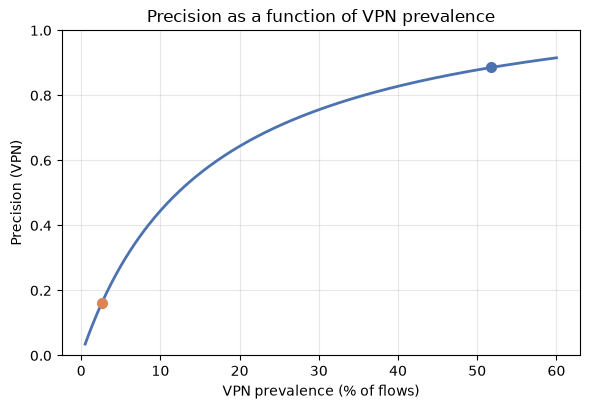

  prevalence  51.8%  ->  precision 0.886
  prevalence  10.0%  ->  precision 0.445
  prevalence   5.0%  ->  precision 0.275
  prevalence   2.6%  ->  precision 0.162
  prevalence   1.0%  ->  precision 0.068


In [32]:
tpr_obs = recall_score(y_test, y_pred)
fpr_obs = fp / (fp + tn)

def precision_at(p):
    return (p*tpr_obs) / (p*tpr_obs + (1-p)*fpr_obs)

prev = np.linspace(0.005, 0.60, 400)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(prev*100, [precision_at(p) for p in prev], color="#4C72B0", lw=2)
ax.plot(51.8, precision_at(0.518), "o", color="#4C72B0", ms=7)   # benchmark
ax.plot(2.6,  precision_at(0.026), "o", color="#DD8452", ms=7)   # measured ISP
ax.set_xlabel("VPN prevalence (% of flows)"); ax.set_ylabel("Precision (VPN)")
ax.set_ylim(0, 1); ax.grid(alpha=0.3)
ax.set_title("Precision as a function of VPN prevalence")
plt.tight_layout()
plt.savefig(RESULTS / "fig_prevalence.png", dpi=150, bbox_inches="tight")
plt.show()

for p in [0.518, 0.10, 0.05, 0.026, 0.01]:
    print(f"  prevalence {p*100:5.1f}%  ->  precision {precision_at(p):.3f}")

## 5.3 Feature contribution (SQ2)

Every retained feature has a verified definition, so all attributions below are
interpretable.

### 5.3.1 Gain and permutation importance

In [33]:
gain = pd.Series(final_model.get_booster().get_score(importance_type="gain")) \
         .reindex(feature_cols).fillna(0)
gain_pct = (gain / gain.sum() * 100).sort_values(ascending=False)
print("Gain-based importance (% of total)\n")
print(gain_pct.round(2).to_string())

Gain-based importance (% of total)

max_flowiat           11.20
flowPktsPerSecond     10.58
min_flowiat           10.05
std_flowiat            8.28
mean_flowiat           7.85
flowBytesPerSecond     7.45
max_active             6.39
max_idle               5.84
min_idle               5.26
duration               5.18
mean_idle              4.84
min_active             4.63
mean_active            4.22
std_idle               4.12
std_active             4.09


In [34]:
# Computed on the test set: shuffling a feature is only meaningful on unseen data.
# This is interpretation of a fixed model; no selection follows.
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
perm_df = (pd.DataFrame({"feature": feature_cols,
                         "drop_in_auc": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("drop_in_auc", ascending=False).reset_index(drop=True))
print(perm_df.round(4).to_string(index=False))

           feature  drop_in_auc    std
flowBytesPerSecond       0.0932 0.0034
       min_flowiat       0.0739 0.0029
       max_flowiat       0.0332 0.0018
 flowPktsPerSecond       0.0309 0.0014
       std_flowiat       0.0293 0.0022
      mean_flowiat       0.0191 0.0011
          duration       0.0164 0.0009
         mean_idle       0.0059 0.0009
          max_idle       0.0029 0.0004
        min_active       0.0024 0.0005
          min_idle       0.0023 0.0004
        max_active       0.0020 0.0004
       mean_active       0.0013 0.0004
        std_active       0.0006 0.0001
          std_idle       0.0005 0.0001


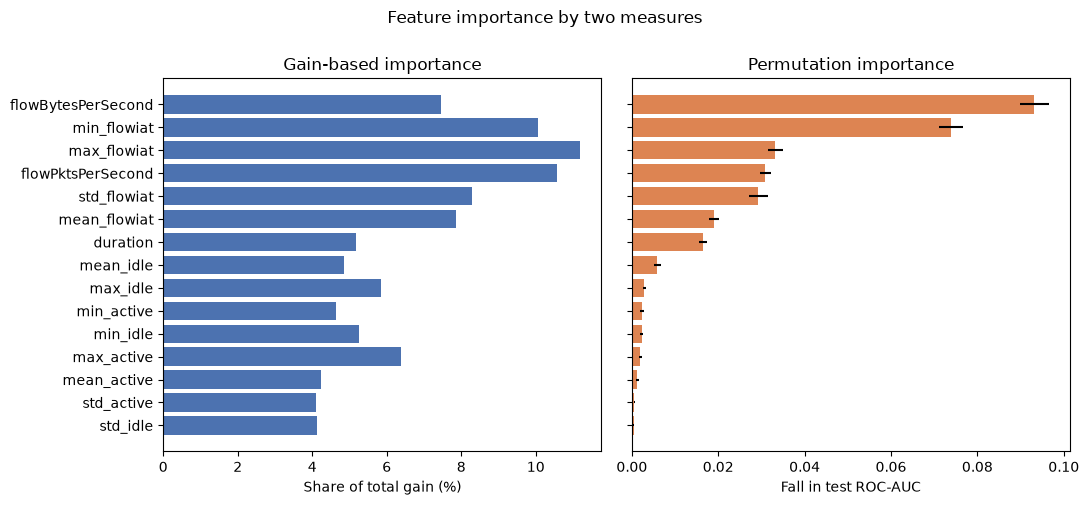

In [35]:
order = perm_df["feature"].tolist()[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
axes[0].barh(order, gain_pct.reindex(order).values, color="#4C72B0")
axes[0].set_xlabel("Share of total gain (%)"); axes[0].set_title("Gain-based importance")
pm = perm_df.set_index("feature").reindex(order)
axes[1].barh(order, pm["drop_in_auc"], xerr=pm["std"], color="#DD8452")
axes[1].set_xlabel("Fall in test ROC-AUC"); axes[1].set_title("Permutation importance")
fig.suptitle("Feature importance by two measures", y=1.0)
plt.tight_layout()
plt.savefig(RESULTS / "fig_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3.2 SHAP analysis

Shapley additive explanations attribute each individual prediction among the features that
produced it, giving both an overall ranking and an account of how particular values
influence particular decisions.

![SHAP summary](../results/fig_shap.png)

*SHAP summary for the tuned model on the test set. Each point is one flow; colour
indicates the value of the feature and horizontal position its contribution to that flow's
prediction.*

*Relocated from the report during the word-budget trim (2026-09-13).*


SHAP importance (mean |SHAP|)

min_flowiat           0.9134
flowBytesPerSecond    0.7881
std_flowiat           0.6491
max_flowiat           0.5369
flowPktsPerSecond     0.5328
mean_flowiat          0.4252
duration              0.3543
mean_idle             0.2150
min_active            0.1593
mean_active           0.1416
max_active            0.1387
max_idle              0.1209
min_idle              0.1088
std_idle              0.0404
std_active            0.0363

Top 5 account for 66.3% of total attribution
Largest single share: 17.7%  (min_flowiat)


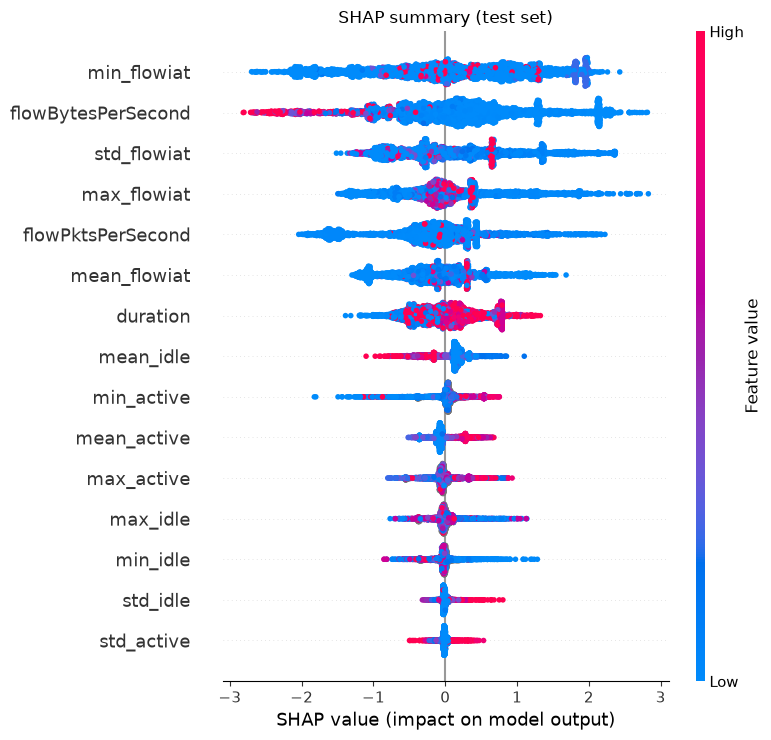

In [36]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols)

print("SHAP importance (mean |SHAP|)\n")
print(mean_abs.sort_values(ascending=False).round(4).to_string())
print(f"\nTop 5 account for "
      f"{100*mean_abs.nlargest(5).sum()/mean_abs.sum():.1f}% of total attribution")
print(f"Largest single share: "
      f"{100*mean_abs.max()/mean_abs.sum():.1f}%  ({mean_abs.idxmax()})")

shap.summary_plot(shap_values, X_test, feature_names=feature_cols,
                  max_display=len(feature_cols), show=False)
plt.title("SHAP summary (test set)")
plt.tight_layout()
plt.savefig(RESULTS / "fig_shap.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3.3 Comparison with univariate separation

Whether the model relies on the features that separate the classes on their own.

![Rank comparison](../results/fig_rank_comparison.png)

*Rank by univariate separation against rank by SHAP attribution. Points on the diagonal
contribute as much within the model as they do alone.*

Minimum flow inter-arrival time ranks sixth of fifteen on its own but first within the
model, and mean active time falls from seventh to tenth. Features that separate the classes
moderately in isolation can therefore assume greater importance once other features are
available to condition on, and the converse also occurs. The agreement is nonetheless
substantially stronger than the divergence that would arise where features cannot be
identified, and the two perspectives support the same conclusion.

![Distribution of the four most discriminative features](../results/fig_top_distributions.png)

*Distribution of the four most discriminative features by class, on logarithmic axes.*

These distributions show why the class differences do not by themselves produce a reliable
detector. The two classes occupy different positions on every axis, but their distributions
overlap substantially throughout. A threshold placed anywhere on a single feature would
misclassify a considerable proportion of both classes, which is why the most discriminative
feature alone reaches only 0.621.

*Relocated from the report during the word-budget trim (2026-09-13).*


In [37]:
comparison = pd.DataFrame({
    "univariate":  sep.set_index("feature")["sep_AUC"],
    "gain":        gain_pct,
    "permutation": perm_df.set_index("feature")["drop_in_auc"],
    "shap":        mean_abs,
})
ranks = comparison.rank(ascending=False).astype(int).sort_values("shap")
print("Rank by each measure (1 = most important)\n")
print(ranks.to_string())
print("\nSpearman correlation between measures:\n")
print(comparison.corr(method="spearman").round(3).to_string())

Rank by each measure (1 = most important)

                    univariate  gain  permutation  shap
min_flowiat                  6     3            2     1
flowBytesPerSecond           1     6            1     2
std_flowiat                  4     4            5     3
max_flowiat                  4     1            3     4
flowPktsPerSecond            2     2            4     5
mean_flowiat                 3     5            6     6
duration                     8    10            7     7
mean_idle                    9    11            8     8
min_active                  10    12           10     9
mean_active                  7    13           13    10
max_active                  11     7           12    11
max_idle                    12     8            9    12
min_idle                    15     9           11    13
std_idle                    14    14           15    14
std_active                  13    15           14    15

Spearman correlation between measures:

             univari

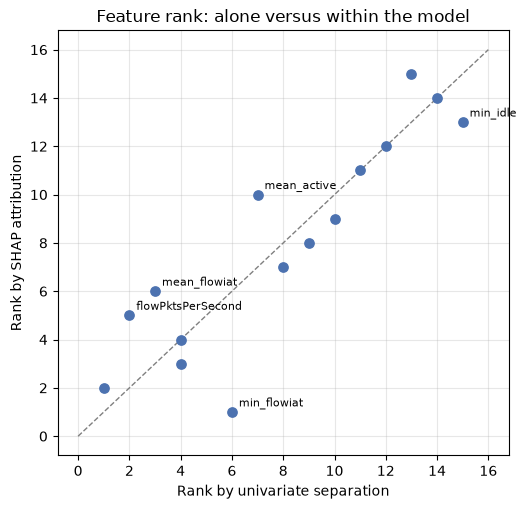

In [38]:
fig, ax = plt.subplots(figsize=(5.4, 5.2))
ax.scatter(ranks["univariate"], ranks["shap"], s=45, color="#4C72B0", zorder=3)
lim = len(feature_cols) + 1
ax.plot([0, lim], [0, lim], "--", color="grey", lw=1)     # perfect agreement
moved = (ranks["univariate"] - ranks["shap"]).abs().sort_values(ascending=False).head(5)
for f in moved.index:
    ax.annotate(f, (ranks.loc[f,"univariate"], ranks.loc[f,"shap"]),
                xytext=(5,4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Rank by univariate separation")
ax.set_ylabel("Rank by SHAP attribution")
ax.set_title("Feature rank: alone versus within the model")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "fig_rank_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Reproducibility record

Versions, seed, feature decisions and results in one file, for report section 4.5.

In [39]:
config = json.loads(final_model.get_booster().save_config())
tp = config["learner"]["gradient_booster"]["tree_train_param"]

record = {
    "python": sys.version.split()[0],
    "xgboost": xgb.__version__,
    "scikit_learn": sklearn.__version__,
    "seed": SEED,
    "n_flows_raw": int(len(df)),
    "n_flows_clean": int(len(df_clean)),
    "n_features": len(feature_cols),
    "features": feature_cols,
    "excluded_features": excluded,
    "best_params": search.best_params_,
    "cv_roc_auc": round(float(search.best_score_), 4),
    "test_roc_auc": round(float(roc_auc_score(y_test, y_proba)), 4),
}

final_model.save_model(RESULTS / "final_model.json")
(RESULTS / "run_record.json").write_text(json.dumps(record, indent=2))
print(json.dumps(record, indent=2))

{
  "python": "3.11.15",
  "xgboost": "3.2.0",
  "scikit_learn": "1.9.0",
  "seed": 42,
  "n_flows_raw": 18758,
  "n_flows_clean": 18036,
  "n_features": 15,
  "features": [
    "duration",
    "flowPktsPerSecond",
    "flowBytesPerSecond",
    "min_flowiat",
    "max_flowiat",
    "mean_flowiat",
    "std_flowiat",
    "min_active",
    "mean_active",
    "max_active",
    "std_active",
    "min_idle",
    "mean_idle",
    "max_idle",
    "std_idle"
  ],
  "excluded_features": [
    "total_fiat",
    "total_biat",
    "min_fiat",
    "min_biat",
    "max_fiat",
    "max_biat",
    "mean_fiat",
    "mean_biat"
  ],
  "best_params": {
    "subsample": 0.8,
    "reg_lambda": 1,
    "n_estimators": 600,
    "min_child_weight": 3,
    "max_depth": 8,
    "learning_rate": 0.05,
    "gamma": 0.1,
    "colsample_bytree": 0.7
  },
  "cv_roc_auc": 0.9642,
  "test_roc_auc": 0.9653
}


In [40]:
top = ["flowBytesPerSecond", "flowPktsPerSecond", "min_flowiat",
       "mean_flowiat", "std_flowiat", "max_flowiat", "duration"]

rows = []
for c in top:
    v = train.loc[train.label == 1, c].dropna()    # VPN
    n = train.loc[train.label == 0, c].dropna()    # non-VPN
    rows.append({
        "feature":       c,
        "median_VPN":    v.median(),
        "median_nonVPN": n.median(),
        "ratio_VPN_over_nonVPN": v.median() / n.median(),
    })

comp = pd.DataFrame(rows)
display(comp.round(2))

,feature,median_VPN,median_nonVPN,ratio_VPN_over_nonVPN
0,flowBytesPerSecond,1600.47,10319.09,0.16
1,flowPktsPerSecond,9.03,41.59,0.22
2,min_flowiat,20.00,14.00,1.43
3,mean_flowiat,137721.75,26061.74,5.28
4,std_flowiat,196004.58,13911.35,14.09
5,max_flowiat,922339.00,172420.00,5.35
6,duration,10079131.00,13295457.50,0.76


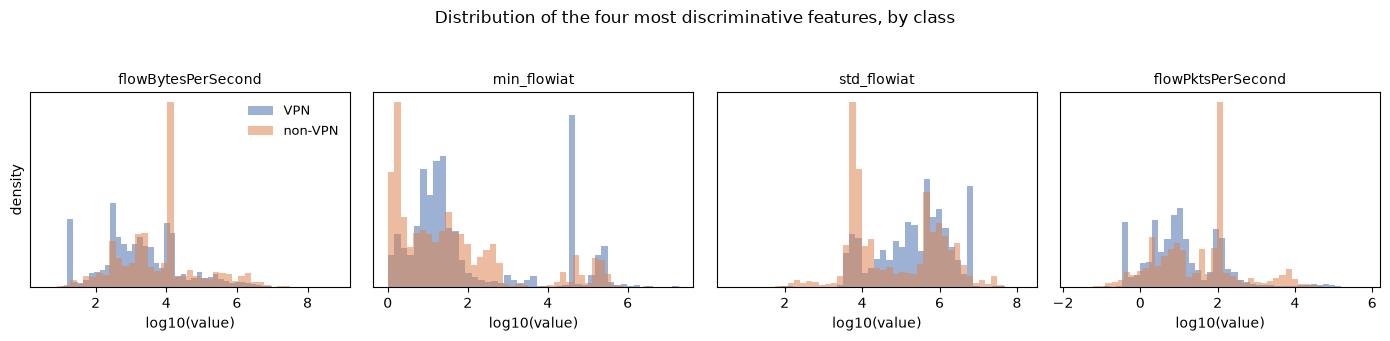

In [41]:
show = ["flowBytesPerSecond", "min_flowiat", "std_flowiat", "flowPktsPerSecond"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, c in zip(axes, show):
    for lab, col, name in [(1, "#4C72B0", "VPN"), (0, "#DD8452", "non-VPN")]:
        v = train.loc[train.label == lab, c].dropna()
        v = v[v > 0]                       # log scale needs positive values
        ax.hist(np.log10(v), bins=45, alpha=0.55, color=col, label=name, density=True)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("log10(value)")
    ax.set_yticks([])
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Distribution of the four most discriminative features, by class", y=1.05)
plt.tight_layout()
plt.savefig(RESULTS / "fig_top_distributions.png", dpi=150, bbox_inches="tight")
plt.show()